In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import pairwise_distances

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


In [2]:
# Memuat dataset asli
df_original = pd.read_csv(
    "../dataset/laptop_price.csv",
    encoding="latin1"
)

# Memuat fitur hasil preprocessing
X_scaled = pd.read_csv(
    "../dataset/laptop_features_scaled.csv"
)

# Memuat hasil clustering FCM
df_fcm = pd.read_csv(
    "../dataset/laptop_fcm_results.csv"
)

# Memuat pusat cluster FCM
cntr = np.load(
    "../dataset/fcm_centers.npy"
)

print("Seluruh data berhasil dimuat!")
print("Dataset asli:", df_original.shape)
print("Fitur normalisasi:", X_scaled.shape)
print("Hasil FCM:", df_fcm.shape)
print("Cluster centers:", cntr.shape)

Seluruh data berhasil dimuat!
Dataset asli: (1303, 13)
Fitur normalisasi: (1303, 7)
Hasil FCM: (1303, 12)
Cluster centers: (4, 7)


In [3]:
print("Contoh dataset asli:")
display(df_original.head())

print("\nContoh fitur hasil preprocessing:")
display(X_scaled.head())

print("\nKolom hasil FCM:")
print(df_fcm.columns.tolist())

Contoh dataset asli:


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60



Contoh fitur hasil preprocessing:


,Price_euros,Ram_GB,Weight_kg,SSD_GB,HDD_GB,CPU_Family_Score,CPU_Base_GHz
0,0.573361,0.357182,0.169576,0.701024,0.0,0.666667,0.518519
1,0.461116,0.357182,0.162095,0.000000,0.0,0.666667,0.333333
2,0.335465,0.357182,0.291771,0.800450,0.0,0.666667,0.592593
3,0.753120,0.563956,0.284289,0.900155,0.0,1.000000,0.666667
4,0.657037,0.357182,0.169576,0.800450,0.0,0.666667,0.814815



Kolom hasil FCM:
['Price_euros', 'Ram_GB', 'Weight_kg', 'SSD_GB', 'HDD_GB', 'CPU_Family_Score', 'CPU_Base_GHz', 'Cluster', 'Membership_Cluster_1', 'Membership_Cluster_2', 'Membership_Cluster_3', 'Membership_Cluster_4']


In [4]:
# Menggabungkan fitur hasil preprocessing dengan hasil FCM
membership_columns = [
    "Membership_Cluster_1",
    "Membership_Cluster_2",
    "Membership_Cluster_3",
    "Membership_Cluster_4"
]

df_knn = X_scaled.copy()

df_knn["Cluster"] = df_fcm["Cluster"]

for col in membership_columns:
    df_knn[col] = df_fcm[col]

print("Dataset untuk KNN berhasil dibuat!")
print("Dimensi dataset:", df_knn.shape)
print("\nDaftar kolom:")
print(df_knn.columns.tolist())

display(df_knn.head())

Dataset untuk KNN berhasil dibuat!
Dimensi dataset: (1303, 12)

Daftar kolom:
['Price_euros', 'Ram_GB', 'Weight_kg', 'SSD_GB', 'HDD_GB', 'CPU_Family_Score', 'CPU_Base_GHz', 'Cluster', 'Membership_Cluster_1', 'Membership_Cluster_2', 'Membership_Cluster_3', 'Membership_Cluster_4']


,Price_euros,Ram_GB,Weight_kg,SSD_GB,HDD_GB,CPU_Family_Score,CPU_Base_GHz,Cluster,Membership_Cluster_1,Membership_Cluster_2,Membership_Cluster_3,Membership_Cluster_4
0,0.573361,0.357182,0.169576,0.701024,0.0,0.666667,0.518519,3,0.029546,0.049878,0.880730,0.039846
1,0.461116,0.357182,0.162095,0.000000,0.0,0.666667,0.333333,2,0.215166,0.422223,0.247747,0.114864
2,0.335465,0.357182,0.291771,0.800450,0.0,0.666667,0.592593,3,0.043088,0.071337,0.824008,0.061568
3,0.753120,0.563956,0.284289,0.900155,0.0,1.000000,0.666667,3,0.049493,0.053462,0.783319,0.113726
4,0.657037,0.357182,0.169576,0.800450,0.0,0.666667,0.814815,3,0.051400,0.068501,0.797965,0.082134


In [5]:
# Menentukan fitur yang digunakan oleh KNN
knn_features = [
    "Price_euros",
    "Ram_GB",
    "Weight_kg",
    "SSD_GB",
    "HDD_GB",
    "CPU_Family_Score",
    "CPU_Base_GHz",
    "Membership_Cluster_1",
    "Membership_Cluster_2",
    "Membership_Cluster_3",
    "Membership_Cluster_4"
]

X_knn = df_knn[knn_features]

print("Fitur KNN berhasil ditentukan!")
print("Jumlah fitur:", len(knn_features))
print("Dimensi X_knn:", X_knn.shape)

Fitur KNN berhasil ditentukan!
Jumlah fitur: 11
Dimensi X_knn: (1303, 11)


In [6]:
# Membuat model KNN
knn_model = NearestNeighbors(
    n_neighbors=5,
    metric="euclidean",
    algorithm="brute"
)

# Melatih model menggunakan dataset
knn_model.fit(X_knn)

print("Model KNN berhasil dibuat!")
print("Jumlah data yang digunakan:", X_knn.shape[0])
print("Jumlah tetangga terdekat:", knn_model.n_neighbors)
print("Metrik jarak:", knn_model.metric)

Model KNN berhasil dibuat!
Jumlah data yang digunakan: 1303
Jumlah tetangga terdekat: 5
Metrik jarak: euclidean


In [7]:
# Mengambil satu laptop sebagai contoh input
query_index = 0

query_data = X_knn.iloc[[query_index]]

# Mencari 5 tetangga terdekat
distances, indices = knn_model.kneighbors(query_data)

print("Indeks laptop yang menjadi input:", query_index)
print("\nHasil pencarian tetangga terdekat:")

for i, (idx, distance) in enumerate(zip(indices[0], distances[0])):
    print(
        f"Rekomendasi {i+1}: "
        f"Indeks={idx}, "
        f"Jarak={distance:.4f}"
    )

Indeks laptop yang menjadi input: 0

Hasil pencarian tetangga terdekat:
Rekomendasi 1: Indeks=0, Jarak=0.0000
Rekomendasi 2: Indeks=495, Jarak=0.0772
Rekomendasi 3: Indeks=989, Jarak=0.1082
Rekomendasi 4: Indeks=1072, Jarak=0.1107
Rekomendasi 5: Indeks=1087, Jarak=0.1111


In [8]:
# Mengambil 6 tetangga terdekat agar tersedia 5 rekomendasi
# setelah laptop input dikeluarkan
distances, indices = knn_model.kneighbors(
    query_data,
    n_neighbors=6
)

# Mengeluarkan laptop input dari hasil rekomendasi
recommendation_indices = []
recommendation_distances = []

for idx, distance in zip(indices[0], distances[0]):
    if idx != query_index:
        recommendation_indices.append(idx)
        recommendation_distances.append(distance)

    if len(recommendation_indices) == 5:
        break

# Membuat tabel rekomendasi
recommendations = df_original.iloc[recommendation_indices][
    ["Company", "Product", "TypeName", "Ram", "Memory",
     "Cpu", "Weight", "Price_euros"]
].copy()

recommendations.insert(
    0, "Recommendation",
    range(1, len(recommendations) + 1)
)

recommendations["Distance"] = recommendation_distances

display(recommendations)

,Recommendation,Company,Product,TypeName,Ram,Memory,Cpu,Weight,Price_euros,Distance
495,1,Lenovo,Thinkpad X260,Ultrabook,8GB,180GB SSD,Intel Core i5 6200U 2.3GHz,1.3kg,1099.00,0.077176
989,2,Dell,Latitude 5480,Notebook,8GB,128GB SSD,Intel Core i5 7200U 2.5GHz,1.6kg,1119.00,0.108203
1072,3,HP,EliteBook 820,Ultrabook,8GB,256GB SSD,Intel Core i5 6200U 2.3GHz,1.26kg,1199.00,0.110687
1087,4,Lenovo,ThinkPad T460,Notebook,8GB,180GB SSD,Intel Core i5 6200U 2.3GHz,1.7kg,1199.00,0.111096
15,5,Apple,MacBook Pro,Ultrabook,8GB,256GB SSD,Intel Core i5 2.3GHz,1.37kg,1518.55,0.111165


In [9]:
# Menampilkan laptop yang menjadi input
query_laptop = df_original.iloc[query_index]

print("LAPTOP INPUT")
display(
    query_laptop[
        ["Company", "Product", "TypeName", "Ram",
         "Memory", "Cpu", "Weight", "Price_euros"]
    ].to_frame().T
)

print("\n5 REKOMENDASI LAPTOP")
display(recommendations)

LAPTOP INPUT


,Company,Product,TypeName,Ram,Memory,Cpu,Weight,Price_euros
0,Apple,MacBook Pro,Ultrabook,8GB,128GB SSD,Intel Core i5 2.3GHz,1.37kg,1339.69



5 REKOMENDASI LAPTOP


,Recommendation,Company,Product,TypeName,Ram,Memory,Cpu,Weight,Price_euros,Distance
495,1,Lenovo,Thinkpad X260,Ultrabook,8GB,180GB SSD,Intel Core i5 6200U 2.3GHz,1.3kg,1099.00,0.077176
989,2,Dell,Latitude 5480,Notebook,8GB,128GB SSD,Intel Core i5 7200U 2.5GHz,1.6kg,1119.00,0.108203
1072,3,HP,EliteBook 820,Ultrabook,8GB,256GB SSD,Intel Core i5 6200U 2.3GHz,1.26kg,1199.00,0.110687
1087,4,Lenovo,ThinkPad T460,Notebook,8GB,180GB SSD,Intel Core i5 6200U 2.3GHz,1.7kg,1199.00,0.111096
15,5,Apple,MacBook Pro,Ultrabook,8GB,256GB SSD,Intel Core i5 2.3GHz,1.37kg,1518.55,0.111165


In [10]:
import re
from sklearn.preprocessing import MinMaxScaler

# Membuat salinan dataset asli
df_preprocessed = df_original.copy()

# 1. Mengubah RAM menjadi numerik (GB)
df_preprocessed["Ram_GB"] = (
    df_preprocessed["Ram"]
    .str.extract(r"(\d+)")
    .astype(float)
)

# 2. Mengubah berat menjadi numerik (kg)
df_preprocessed["Weight_kg"] = (
    df_preprocessed["Weight"]
    .str.extract(r"([\d.]+)")
    .astype(float)
)

# 3. Memisahkan kapasitas penyimpanan
memory_columns = ["SSD_GB", "HDD_GB", "Flash_GB", "Hybrid_GB"]

for col in memory_columns:
    df_preprocessed[col] = 0.0

memory_pattern = (
    r"(\d+(?:\.\d+)?)\s*(TB|GB)\s*"
    r"(SSD|HDD|FLASH STORAGE|HYBRID)"
)

for index, memory in df_preprocessed["Memory"].items():
    matches = re.finditer(memory_pattern, str(memory).upper())

    for match in matches:
        capacity = float(match.group(1))
        unit = match.group(2)
        storage_type = match.group(3)

        if unit == "TB":
            capacity *= 1024

        if storage_type == "SSD":
            df_preprocessed.loc[index, "SSD_GB"] += capacity
        elif storage_type == "HDD":
            df_preprocessed.loc[index, "HDD_GB"] += capacity
        elif storage_type == "FLASH STORAGE":
            df_preprocessed.loc[index, "Flash_GB"] += capacity
        elif storage_type == "HYBRID":
            df_preprocessed.loc[index, "Hybrid_GB"] += capacity

# 4. Mengubah keluarga prosesor menjadi skor numerik
def get_cpu_family_score(cpu):
    cpu = str(cpu).lower()

    if re.search(r"\bi9\b", cpu):
        return 9
    elif re.search(r"\bi7\b", cpu):
        return 7
    elif re.search(r"\bi5\b", cpu):
        return 5
    elif re.search(r"\bi3\b", cpu):
        return 3
    elif "core m" in cpu:
        return 2
    elif "celeron" in cpu:
        return 1
    elif "pentium" in cpu:
        return 2
    elif "atom" in cpu:
        return 1
    elif "amd" in cpu:
        return 3
    else:
        return 1

df_preprocessed["CPU_Family_Score"] = (
    df_preprocessed["Cpu"].apply(get_cpu_family_score)
)

# 5. Mengambil frekuensi dasar prosesor
df_preprocessed["CPU_Base_GHz"] = (
    df_preprocessed["Cpu"]
    .str.extract(r"(\d+(?:\.\d+)?)\s*GHz", flags=re.IGNORECASE)
    .astype(float)
)

# Memastikan tidak ada nilai kosong pada fitur yang digunakan
feature_columns = [
    "Price_euros",
    "Ram_GB",
    "Weight_kg",
    "SSD_GB",
    "HDD_GB",
    "CPU_Family_Score",
    "CPU_Base_GHz"
]

print("Jumlah nilai kosong:")
print(df_preprocessed[feature_columns].isnull().sum())

Jumlah nilai kosong:
Price_euros         0
Ram_GB              0
Weight_kg           0
SSD_GB              0
HDD_GB              0
CPU_Family_Score    0
CPU_Base_GHz        0
dtype: int64


In [11]:
# Mengambil tujuh fitur yang digunakan oleh model
X_rebuilt = df_preprocessed[feature_columns].copy()

# Menerapkan log1p pada fitur yang sebelumnya ditransformasikan
log_columns = [
    "Price_euros",
    "Ram_GB",
    "SSD_GB",
    "HDD_GB"
]

X_rebuilt[log_columns] = np.log1p(X_rebuilt[log_columns])

# Membangun kembali MinMaxScaler
scaler = MinMaxScaler()

X_rebuilt_scaled = scaler.fit_transform(X_rebuilt)

X_rebuilt_scaled = pd.DataFrame(
    X_rebuilt_scaled,
    columns=feature_columns
)

# Membandingkan dengan hasil preprocessing sebelumnya
max_difference = np.max(
    np.abs(X_rebuilt_scaled.values - X_scaled.values)
)

print("Scaler berhasil dibangun kembali!")
print("Dimensi:", X_rebuilt_scaled.shape)
print("Perbedaan maksimum dengan data sebelumnya:", max_difference)

if np.allclose(
    X_rebuilt_scaled.values,
    X_scaled.values,
    atol=1e-6
):
    print("VALIDASI BERHASIL: Hasil preprocessing konsisten.")
else:
    print("VALIDASI BELUM BERHASIL: Ada perbedaan hasil preprocessing.")

Scaler berhasil dibangun kembali!
Dimensi: (1303, 7)
Perbedaan maksimum dengan data sebelumnya: 1.1102230246251565e-16
VALIDASI BERHASIL: Hasil preprocessing konsisten.


In [13]:
import skfuzzy as fuzz

# Mengambil satu data laptop sebagai sampel pengujian
test_input_scaled = X_scaled.iloc[[0]].values.T

# Menghitung derajat keanggotaan menggunakan pusat cluster FCM
test_membership, _, _, _, _, _ = fuzz.cluster.cmeans_predict(
    test_input_scaled,
    cntr,
    m=2,
    error=0.005,
    maxiter=1000,
    seed=42
)

print("Penghitungan membership FCM berhasil!")
print("\nDerajat keanggotaan:")

for i, membership in enumerate(test_membership[:, 0]):
    print(f"Cluster {i+1}: {membership:.6f}")

print("\nTotal membership:", test_membership[:, 0].sum())

Penghitungan membership FCM berhasil!

Derajat keanggotaan:
Cluster 1: 0.029546
Cluster 2: 0.049878
Cluster 3: 0.880730
Cluster 4: 0.039846

Total membership: 1.0


In [14]:
# Membandingkan membership hasil prediksi dengan hasil FCM sebelumnya
original_membership = df_fcm.loc[
    0,
    membership_columns
].values.astype(float)

predicted_membership = test_membership[:, 0]

comparison = pd.DataFrame({
    "Cluster": [1, 2, 3, 4],
    "Membership_FCM_Awal": original_membership,
    "Membership_Prediksi": predicted_membership
})

comparison["Difference"] = abs(
    comparison["Membership_FCM_Awal"] -
    comparison["Membership_Prediksi"]
)

display(comparison)

print(
    "\nPerbedaan maksimum:",
    comparison["Difference"].max()
)

,Cluster,Membership_FCM_Awal,Membership_Prediksi,Difference
0,1,0.029546,0.029546,4.163336e-17
1,2,0.049878,0.049878,6.245005e-17
2,3,0.880730,0.880730,0.000000e+00
3,4,0.039846,0.039846,2.081668e-17



Perbedaan maksimum: 6.245004513516506e-17


In [15]:
# Menggabungkan 7 fitur hasil preprocessing
# dengan 4 derajat keanggotaan FCM

query_features = np.concatenate([
    test_input_scaled.flatten(),
    test_membership[:, 0]
])

# Mengubah menjadi DataFrame dengan nama kolom yang sesuai
query_knn = pd.DataFrame(
    [query_features],
    columns=knn_features
)

print("Input KNN berhasil dibuat!")
print("Dimensi input:", query_knn.shape)

display(query_knn)

Input KNN berhasil dibuat!
Dimensi input: (1, 11)


,Price_euros,Ram_GB,Weight_kg,SSD_GB,HDD_GB,CPU_Family_Score,CPU_Base_GHz,Membership_Cluster_1,Membership_Cluster_2,Membership_Cluster_3,Membership_Cluster_4
0,0.573361,0.357182,0.169576,0.701024,0.0,0.666667,0.518519,0.029546,0.049878,0.88073,0.039846


In [16]:
# Mencari 5 laptop terdekat dari input
distances, indices = knn_model.kneighbors(
    query_knn,
    n_neighbors=5
)

# Mengambil hasil rekomendasi
recommendations_new = df_original.iloc[indices[0]][
    ["Company", "Product", "TypeName", "Ram",
     "Memory", "Cpu", "Weight", "Price_euros"]
].copy()

recommendations_new.insert(
    0,
    "Recommendation",
    range(1, 6)
)

recommendations_new["Distance"] = distances[0]

print("HASIL REKOMENDASI LAPTOP")
display(recommendations_new)

HASIL REKOMENDASI LAPTOP


,Recommendation,Company,Product,TypeName,Ram,Memory,Cpu,Weight,Price_euros,Distance
0,1,Apple,MacBook Pro,Ultrabook,8GB,128GB SSD,Intel Core i5 2.3GHz,1.37kg,1339.69,0.000000
495,2,Lenovo,Thinkpad X260,Ultrabook,8GB,180GB SSD,Intel Core i5 6200U 2.3GHz,1.3kg,1099.00,0.077176
989,3,Dell,Latitude 5480,Notebook,8GB,128GB SSD,Intel Core i5 7200U 2.5GHz,1.6kg,1119.00,0.108203
1072,4,HP,EliteBook 820,Ultrabook,8GB,256GB SSD,Intel Core i5 6200U 2.3GHz,1.26kg,1199.00,0.110687
1087,5,Lenovo,ThinkPad T460,Notebook,8GB,180GB SSD,Intel Core i5 6200U 2.3GHz,1.7kg,1199.00,0.111096


In [19]:
def recommend_laptops(
    price,
    ram,
    weight,
    ssd,
    hdd,
    cpu_score,
    cpu_ghz,
    n_recommendations=5
):
    # Membuat DataFrame input
    new_data = pd.DataFrame([{
        "Price_euros": price,
        "Ram_GB": ram,
        "Weight_kg": weight,
        "SSD_GB": ssd,
        "HDD_GB": hdd,
        "CPU_Family_Score": cpu_score,
        "CPU_Base_GHz": cpu_ghz
    }])

    # Transformasi log1p
    new_data[log_columns] = np.log1p(
        new_data[log_columns]
    )

    # Normalisasi menggunakan scaler yang sama
    new_scaled = scaler.transform(new_data)

    # Prediksi membership FCM
    membership, _, _, _, _, _ = fuzz.cluster.cmeans_predict(
        new_scaled.T,
        cntr,
        m=2,
        error=0.005,
        maxiter=1000,
        seed=42
    )

    # Menggabungkan 7 fitur dan 4 membership
    query_features = np.concatenate([
        new_scaled.flatten(),
        membership[:, 0]
    ])

    query_knn = pd.DataFrame(
        [query_features],
        columns=knn_features
    )

    # Pencarian laptop terdekat
    distances, indices = knn_model.kneighbors(
        query_knn,
        n_neighbors=n_recommendations
    )

    # Mengambil hasil rekomendasi
    results = df_original.iloc[indices[0]][[
        "Company",
        "Product",
        "TypeName",
        "Ram",
        "Memory",
        "Cpu",
        "Weight",
        "Price_euros"
    ]].copy()

    results.insert(
        0,
        "Recommendation",
        range(1, len(results) + 1)
    )

    results["Distance"] = distances[0]

    return results

In [20]:
# Memeriksa apakah fungsi berhasil didefinisikan
print("Fungsi rekomendasi tersedia:", callable(recommend_laptops))
print("Nama fungsi:", recommend_laptops.__name__)

Fungsi rekomendasi tersedia: True
Nama fungsi: recommend_laptops


In [21]:
result = recommend_laptops(
    price=1200,
    ram=8,
    weight=1.5,
    ssd=256,
    hdd=0,
    cpu_score=5,
    cpu_ghz=2.5,
    n_recommendations=5
)

print("HASIL REKOMENDASI LAPTOP")
display(result)

HASIL REKOMENDASI LAPTOP


,Recommendation,Company,Product,TypeName,Ram,Memory,Cpu,Weight,Price_euros,Distance
383,1,Lenovo,IdeaPad 720S-14IKB,Notebook,8GB,256GB SSD,Intel Core i5 7200U 2.5GHz,1.5kg,1099.00,0.025079
1194,2,Dell,Inspiron 7378,2 in 1 Convertible,8GB,256GB SSD,Intel Core i5 7200U 2.5GHz,1.6kg,1199.00,0.025615
995,3,Asus,ZenBook UX310UA-FB485T,Notebook,8GB,256GB SSD,Intel Core i5 7200U 2.5GHz,1.4kg,1150.00,0.029634
748,4,Dell,Latitude 5480,Notebook,8GB,256GB SSD,Intel Core i5 7200U 2.5GHz,1.6kg,1126.71,0.030769
660,5,Dell,Latitude E7470,Notebook,8GB,256GB SSD,Intel Core i5 6300U 2.4GHz,1.56kg,1229.00,0.040956


In [22]:
from sklearn.neighbors import NearestNeighbors

# Membuat model KNN biasa tanpa membership FCM
knn_baseline = NearestNeighbors(
    n_neighbors=5,
    metric="euclidean",
    algorithm="brute"
)

# Melatih model menggunakan 7 fitur preprocessing
knn_baseline.fit(X_scaled)

print("Model KNN baseline berhasil dibuat!")
print("Jumlah data:", X_scaled.shape[0])
print("Jumlah fitur:", X_scaled.shape[1])
print("Metrik jarak: Euclidean")

Model KNN baseline berhasil dibuat!
Jumlah data: 1303
Jumlah fitur: 7
Metrik jarak: Euclidean


In [25]:
# Membuat input pengujian yang sama dengan FCM-KNN
comparison_input = pd.DataFrame([{
    "Price_euros": 1200,
    "Ram_GB": 8,
    "Weight_kg": 1.5,
    "SSD_GB": 256,
    "HDD_GB": 0,
    "CPU_Family_Score": 5,
    "CPU_Base_GHz": 2.5
}])

# Transformasi log1p
comparison_input[log_columns] = np.log1p(
    comparison_input[log_columns]
)

# Normalisasi menggunakan scaler yang sama
baseline_query = pd.DataFrame(
    scaler.transform(comparison_input),
    columns=feature_columns
)

# Pencarian 5 tetangga terdekat
baseline_distances, baseline_indices = knn_baseline.kneighbors(
    baseline_query,
    n_neighbors=5
)

# Membuat tabel hasil rekomendasi
baseline_result = df_original.iloc[baseline_indices[0]][[
    "Company",
    "Product",
    "TypeName",
    "Ram",
    "Memory",
    "Cpu",
    "Weight",
    "Price_euros"
]].copy()

baseline_result.insert(
    0,
    "Recommendation",
    range(1, 6)
)

baseline_result["Distance"] = baseline_distances[0]

print("HASIL REKOMENDASI KNN BIASA")
display(baseline_result)

HASIL REKOMENDASI KNN BIASA


,Recommendation,Company,Product,TypeName,Ram,Memory,Cpu,Weight,Price_euros,Distance
383,1,Lenovo,IdeaPad 720S-14IKB,Notebook,8GB,256GB SSD,Intel Core i5 7200U 2.5GHz,1.5kg,1099.00,0.024736
1194,2,Dell,Inspiron 7378,2 in 1 Convertible,8GB,256GB SSD,Intel Core i5 7200U 2.5GHz,1.6kg,1199.00,0.024939
995,3,Asus,ZenBook UX310UA-FB485T,Notebook,8GB,256GB SSD,Intel Core i5 7200U 2.5GHz,1.4kg,1150.00,0.027663
748,4,Dell,Latitude 5480,Notebook,8GB,256GB SSD,Intel Core i5 7200U 2.5GHz,1.6kg,1126.71,0.030598
1001,5,HP,ENVY -,Notebook,8GB,256GB SSD,Intel Core i5 7200U 2.5GHz,1.34kg,1189.00,0.039984


In [24]:
# Membandingkan indeks laptop yang direkomendasikan
baseline_indices_set = set(baseline_result.index)
hybrid_indices_set = set(result.index)

common_indices = baseline_indices_set.intersection(
    hybrid_indices_set
)

print("PERBANDINGAN KNN DAN FCM-KNN")
print("Jumlah rekomendasi KNN:", len(baseline_indices_set))
print("Jumlah rekomendasi FCM-KNN:", len(hybrid_indices_set))
print("Laptop yang muncul pada kedua metode:", len(common_indices))

print("\nLaptop yang direkomendasikan oleh kedua metode:")

if common_indices:
    display(
        df_original.loc[list(common_indices), [
            "Company",
            "Product",
            "Price_euros"
        ]]
    )
else:
    print("Tidak ada laptop yang sama pada kedua hasil.")

PERBANDINGAN KNN DAN FCM-KNN
Jumlah rekomendasi KNN: 5
Jumlah rekomendasi FCM-KNN: 5
Laptop yang muncul pada kedua metode: 4

Laptop yang direkomendasikan oleh kedua metode:


,Company,Product,Price_euros
1194,Dell,Inspiron 7378,1199.00
995,Asus,ZenBook UX310UA-FB485T,1150.00
748,Dell,Latitude 5480,1126.71
383,Lenovo,IdeaPad 720S-14IKB,1099.00


In [26]:
# Menguji beberapa variasi spesifikasi laptop
test_profiles = {
    "Profil A - Ekonomis": {
        "price": 700,
        "ram": 8,
        "weight": 1.3,
        "ssd": 256,
        "hdd": 0,
        "cpu_score": 3,
        "cpu_ghz": 2.4
    },
    "Profil B - Produktivitas": {
        "price": 1200,
        "ram": 16,
        "weight": 1.6,
        "ssd": 512,
        "hdd": 0,
        "cpu_score": 7,
        "cpu_ghz": 2.8
    },
    "Profil C - Performa Tinggi": {
        "price": 2000,
        "ram": 32,
        "weight": 2.2,
        "ssd": 1024,
        "hdd": 0,
        "cpu_score": 9,
        "cpu_ghz": 3.2
    }
}

for profile_name, specs in test_profiles.items():
    print("\n" + "=" * 60)
    print(profile_name)
    print("=" * 60)

    profile_result = recommend_laptops(**specs)

    display(profile_result[[
        "Recommendation",
        "Company",
        "Product",
        "Ram",
        "Memory",
        "Cpu",
        "Weight",
        "Price_euros",
        "Distance"
    ]])


Profil A - Ekonomis


,Recommendation,Company,Product,Ram,Memory,Cpu,Weight,Price_euros,Distance
498,1,Lenovo,ThinkPad 13,8GB,256GB SSD,Intel Core i3 7100U 2.4GHz,1.4kg,949.0,0.097077
829,2,Acer,Swift 3,8GB,128GB SSD,Intel Core i3 7100U 2.4GHz,1.5kg,619.0,0.139528
62,3,Lenovo,IdeaPad 520S-14IKB,8GB,256GB SSD,Intel Core i3 7130U 2.7GHz,1.7kg,599.0,0.156758
475,4,Dell,Latitude E5470,8GB,128GB SSD,Intel Core i3 6100U 2.3GHz,1.79kg,740.0,0.173348
98,5,Asus,X541UV-DM1439T (i3-7100U/6GB/256GB/GeForce,6GB,256GB SSD,Intel Core i3 7100U 2.4GHz,2kg,577.0,0.203695



Profil B - Produktivitas


,Recommendation,Company,Product,Ram,Memory,Cpu,Weight,Price_euros,Distance
299,1,Asus,ZenBook UX530UQ-PRO,16GB,512GB SSD,Intel Core i7 7500U 2.7GHz,1.63kg,1468.0,0.069369
1239,2,Lenovo,ThinkPad 13,16GB,512GB SSD,Intel Core i7 7500U 2.7GHz,1.4kg,1499.0,0.088355
891,3,HP,Envy x360,16GB,256GB SSD,Intel Core i7 7500U 2.7GHz,1.42kg,1399.0,0.124165
696,4,Lenovo,Yoga 910-13IKB,16GB,512GB SSD,Intel Core i7 7500U 2.7GHz,1.38kg,1749.0,0.125066
1186,5,Dell,Inspiron 5578,16GB,512GB SSD,Intel Core i7 7500U 2.7GHz,2.09kg,1179.0,0.127885



Profil C - Performa Tinggi


,Recommendation,Company,Product,Ram,Memory,Cpu,Weight,Price_euros,Distance
329,1,Dell,XPS 15,32GB,1TB SSD,Intel Core i7 7700HQ 2.8GHz,2.06kg,2639.0,0.398150
517,2,Asus,ROG Zephyrus,24GB,512GB SSD,Intel Core i7 7700HQ 2.8GHz,2.24kg,2968.0,0.441372
744,3,Lenovo,Thinkpad P51s,16GB,1TB SSD,Intel Core i7 7600U 2.8GHz,2.5kg,3299.0,0.487995
434,4,Lenovo,Thinkpad P51,16GB,512GB SSD,Intel Core i7 7820HQ 2.9GHz,2.5kg,2449.0,0.489445
639,5,Dell,XPS 15,16GB,1TB SSD,Intel Core i7 7700HQ 2.8GHz,2.06kg,2399.0,0.501764


In [27]:
# Membandingkan KNN biasa dan FCM-KNN pada seluruh profil

comparison_summary = []

for profile_name, specs in test_profiles.items():

    # Menyiapkan input dengan preprocessing yang sama
    input_data = pd.DataFrame([{
        "Price_euros": specs["price"],
        "Ram_GB": specs["ram"],
        "Weight_kg": specs["weight"],
        "SSD_GB": specs["ssd"],
        "HDD_GB": specs["hdd"],
        "CPU_Family_Score": specs["cpu_score"],
        "CPU_Base_GHz": specs["cpu_ghz"]
    }])

    input_data[log_columns] = np.log1p(
        input_data[log_columns]
    )

    input_scaled = pd.DataFrame(
        scaler.transform(input_data),
        columns=feature_columns
    )

    # KNN biasa
    base_distances, base_indices = knn_baseline.kneighbors(
        input_scaled,
        n_neighbors=5
    )

    # FCM-KNN
    hybrid_result = recommend_laptops(**specs)

    # Mengambil indeks rekomendasi
    baseline_set = set(base_indices[0])
    hybrid_set = set(hybrid_result.index)

    common = baseline_set.intersection(hybrid_set)
    union = baseline_set.union(hybrid_set)

    # Menghitung kemiripan daftar rekomendasi
    jaccard = len(common) / len(union)

    comparison_summary.append({
        "Profil": profile_name,
        "KNN_Biasa": len(baseline_set),
        "FCM_KNN": len(hybrid_set),
        "Rekomendasi_Sama": len(common),
        "Jaccard_Similarity": jaccard
    })

    print("\n" + "=" * 60)
    print(profile_name)
    print("=" * 60)

    print("\nHasil KNN Biasa:")
    display(
        df_original.iloc[base_indices[0]][[
            "Company", "Product", "Ram",
            "Memory", "Cpu", "Weight", "Price_euros"
        ]]
    )

    print("\nHasil FCM-KNN:")
    display(
        hybrid_result[[
            "Company", "Product", "Ram",
            "Memory", "Cpu", "Weight", "Price_euros"
        ]]
    )

# Ringkasan perbandingan
comparison_summary = pd.DataFrame(comparison_summary)

print("\nRINGKASAN PERBANDINGAN")
display(comparison_summary)


Profil A - Ekonomis

Hasil KNN Biasa:


,Company,Product,Ram,Memory,Cpu,Weight,Price_euros
498,Lenovo,ThinkPad 13,8GB,256GB SSD,Intel Core i3 7100U 2.4GHz,1.4kg,949.0
829,Acer,Swift 3,8GB,128GB SSD,Intel Core i3 7100U 2.4GHz,1.5kg,619.0
62,Lenovo,IdeaPad 520S-14IKB,8GB,256GB SSD,Intel Core i3 7130U 2.7GHz,1.7kg,599.0
475,Dell,Latitude E5470,8GB,128GB SSD,Intel Core i3 6100U 2.3GHz,1.79kg,740.0
98,Asus,X541UV-DM1439T (i3-7100U/6GB/256GB/GeForce,6GB,256GB SSD,Intel Core i3 7100U 2.4GHz,2kg,577.0



Hasil FCM-KNN:


,Company,Product,Ram,Memory,Cpu,Weight,Price_euros
498,Lenovo,ThinkPad 13,8GB,256GB SSD,Intel Core i3 7100U 2.4GHz,1.4kg,949.0
829,Acer,Swift 3,8GB,128GB SSD,Intel Core i3 7100U 2.4GHz,1.5kg,619.0
62,Lenovo,IdeaPad 520S-14IKB,8GB,256GB SSD,Intel Core i3 7130U 2.7GHz,1.7kg,599.0
475,Dell,Latitude E5470,8GB,128GB SSD,Intel Core i3 6100U 2.3GHz,1.79kg,740.0
98,Asus,X541UV-DM1439T (i3-7100U/6GB/256GB/GeForce,6GB,256GB SSD,Intel Core i3 7100U 2.4GHz,2kg,577.0



Profil B - Produktivitas

Hasil KNN Biasa:


,Company,Product,Ram,Memory,Cpu,Weight,Price_euros
299,Asus,ZenBook UX530UQ-PRO,16GB,512GB SSD,Intel Core i7 7500U 2.7GHz,1.63kg,1468.0
1239,Lenovo,ThinkPad 13,16GB,512GB SSD,Intel Core i7 7500U 2.7GHz,1.4kg,1499.0
891,HP,Envy x360,16GB,256GB SSD,Intel Core i7 7500U 2.7GHz,1.42kg,1399.0
696,Lenovo,Yoga 910-13IKB,16GB,512GB SSD,Intel Core i7 7500U 2.7GHz,1.38kg,1749.0
1186,Dell,Inspiron 5578,16GB,512GB SSD,Intel Core i7 7500U 2.7GHz,2.09kg,1179.0


... (4 outputs left out)


Hasil FCM-KNN:


,Company,Product,Ram,Memory,Cpu,Weight,Price_euros
329,Dell,XPS 15,32GB,1TB SSD,Intel Core i7 7700HQ 2.8GHz,2.06kg,2639.0
517,Asus,ROG Zephyrus,24GB,512GB SSD,Intel Core i7 7700HQ 2.8GHz,2.24kg,2968.0
744,Lenovo,Thinkpad P51s,16GB,1TB SSD,Intel Core i7 7600U 2.8GHz,2.5kg,3299.0
434,Lenovo,Thinkpad P51,16GB,512GB SSD,Intel Core i7 7820HQ 2.9GHz,2.5kg,2449.0
639,Dell,XPS 15,16GB,1TB SSD,Intel Core i7 7700HQ 2.8GHz,2.06kg,2399.0



RINGKASAN PERBANDINGAN


,Profil,KNN_Biasa,FCM_KNN,Rekomendasi_Sama,Jaccard_Similarity
0,Profil A - Ekonomis,5,5,5,1.000000
1,Profil B - Produktivitas,5,5,5,1.000000
2,Profil C - Performa Tinggi,5,5,4,0.666667


In [28]:
# Evaluasi kesesuaian spesifikasi rekomendasi

evaluation_features = [
    "Price_euros",
    "Ram_GB",
    "Weight_kg",
    "SSD_GB",
    "HDD_GB",
    "CPU_Family_Score",
    "CPU_Base_GHz"
]

evaluation_results = []

for profile_name, specs in test_profiles.items():

    # Menyiapkan input target
    target = {
        "Price_euros": specs["price"],
        "Ram_GB": specs["ram"],
        "Weight_kg": specs["weight"],
        "SSD_GB": specs["ssd"],
        "HDD_GB": specs["hdd"],
        "CPU_Family_Score": specs["cpu_score"],
        "CPU_Base_GHz": specs["cpu_ghz"]
    }

    # Menghitung input yang telah dinormalisasi
    input_data = pd.DataFrame([target])
    input_data[log_columns] = np.log1p(
        input_data[log_columns]
    )

    input_scaled = pd.DataFrame(
        scaler.transform(input_data),
        columns=feature_columns
    )

    # Hasil KNN biasa
    base_distances, base_indices = knn_baseline.kneighbors(
        input_scaled,
        n_neighbors=5
    )

    # Hasil FCM-KNN
    hybrid_result = recommend_laptops(**specs)

    # Mengambil fitur asli rekomendasi
    base_data = df_preprocessed.iloc[
        base_indices[0]
    ][evaluation_features]

    hybrid_data = df_preprocessed.loc[
        hybrid_result.index,
        evaluation_features
    ]

    # Menghitung rata-rata selisih absolut
    base_error = (
        base_data - pd.Series(target)
    ).abs().mean()

    hybrid_error = (
        hybrid_data - pd.Series(target)
    ).abs().mean()

    for feature in evaluation_features:
        evaluation_results.append({
            "Profil": profile_name,
            "Fitur": feature,
            "KNN_Biasa_MAE": base_error[feature],
            "FCM_KNN_MAE": hybrid_error[feature]
        })

evaluation_df = pd.DataFrame(evaluation_results)

print("HASIL EVALUASI KETEPATAN SPESIFIKASI")
display(evaluation_df.round(4))

HASIL EVALUASI KETEPATAN SPESIFIKASI


,Profil,Fitur,KNN_Biasa_MAE,FCM_KNN_MAE
0,Profil A - Ekonomis,Price_euros,118.800,118.800
1,Profil A - Ekonomis,Ram_GB,0.400,0.400
2,Profil A - Ekonomis,Weight_kg,0.378,0.378
3,Profil A - Ekonomis,SSD_GB,51.200,51.200
4,Profil A - Ekonomis,HDD_GB,0.000,0.000
5,Profil A - Ekonomis,CPU_Family_Score,0.000,0.000
6,Profil A - Ekonomis,CPU_Base_GHz,0.080,0.080
7,Profil B - Produktivitas,Price_euros,267.200,267.200
8,Profil B - Produktivitas,Ram_GB,0.000,0.000
9,Profil B - Produktivitas,Weight_kg,0.224,0.224


In [30]:
# Evaluasi MAE pada skala fitur yang telah dinormalisasi

normalized_evaluation = []

for profile_name, specs in test_profiles.items():

    # Membuat target input
    target = pd.DataFrame([{
        "Price_euros": specs["price"],
        "Ram_GB": specs["ram"],
        "Weight_kg": specs["weight"],
        "SSD_GB": specs["ssd"],
        "HDD_GB": specs["hdd"],
        "CPU_Family_Score": specs["cpu_score"],
        "CPU_Base_GHz": specs["cpu_ghz"]
    }])

    # Transformasi log1p
    target[log_columns] = np.log1p(
        target[log_columns]
    )

    # Normalisasi menggunakan scaler yang sama
    target_scaled = pd.DataFrame(
        scaler.transform(target),
        columns=feature_columns
    )

    # KNN biasa menggunakan input yang sudah dinormalisasi
    base_distances, base_indices = knn_baseline.kneighbors(
        target_scaled,
        n_neighbors=5
    )

    # FCM-KNN
    hybrid_result = recommend_laptops(**specs)

    # Mengambil fitur rekomendasi
    base_data = df_preprocessed.iloc[
        base_indices[0]
    ][feature_columns].copy()

    hybrid_data = df_preprocessed.loc[
        hybrid_result.index,
        feature_columns
    ].copy()

    # Transformasi log1p
    base_data[log_columns] = np.log1p(
        base_data[log_columns]
    )

    hybrid_data[log_columns] = np.log1p(
        hybrid_data[log_columns]
    )

    # Normalisasi rekomendasi
    base_scaled = scaler.transform(base_data)
    hybrid_scaled = scaler.transform(hybrid_data)

    # Menghitung MAE
    base_mae = np.abs(
        base_scaled - target_scaled.values
    ).mean()

    hybrid_mae = np.abs(
        hybrid_scaled - target_scaled.values
    ).mean()

    normalized_evaluation.append({
        "Profil": profile_name,
        "KNN_Biasa_MAE": base_mae,
        "FCM_KNN_MAE": hybrid_mae
    })

normalized_summary = pd.DataFrame(normalized_evaluation)

normalized_summary["Metode_MAE_Lebih_Rendah"] = np.where(
    normalized_summary["KNN_Biasa_MAE"] <
    normalized_summary["FCM_KNN_MAE"],
    "KNN Biasa",
    np.where(
        normalized_summary["KNN_Biasa_MAE"] >
        normalized_summary["FCM_KNN_MAE"],
        "FCM-KNN",
        "Sama"
    )
)

print("PERBANDINGAN MAE TERNORMALISASI")
display(normalized_summary.round(5))

PERBANDINGAN MAE TERNORMALISASI


,Profil,KNN_Biasa_MAE,FCM_KNN_MAE,Metode_MAE_Lebih_Rendah
0,Profil A - Ekonomis,0.03240,0.03240,Sama
1,Profil B - Produktivitas,0.02393,0.02393,Sama
2,Profil C - Performa Tinggi,0.11137,0.11357,KNN Biasa


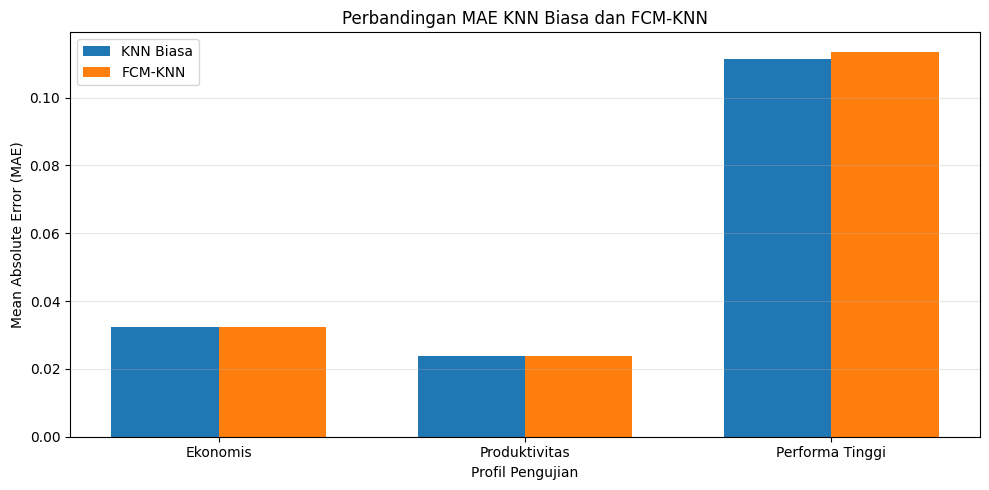

In [31]:
# Visualisasi perbandingan MAE kedua metode

import matplotlib.pyplot as plt
import numpy as np

profiles = normalized_summary["Profil"].tolist()

knn_values = normalized_summary["KNN_Biasa_MAE"].values
fcm_knn_values = normalized_summary["FCM_KNN_MAE"].values

x = np.arange(len(profiles))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width/2,
    knn_values,
    width,
    label="KNN Biasa"
)

plt.bar(
    x + width/2,
    fcm_knn_values,
    width,
    label="FCM-KNN"
)

plt.xticks(
    x,
    ["Ekonomis", "Produktivitas", "Performa Tinggi"]
)

plt.ylabel("Mean Absolute Error (MAE)")
plt.xlabel("Profil Pengujian")
plt.title("Perbandingan MAE KNN Biasa dan FCM-KNN")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:

# Cell 27 - Pengujian sensitivitas jumlah cluster FCM

import skfuzzy as fuzz
import numpy as np
import pandas as pd

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

cluster_values = [3, 4, 5]
m = 2
error = 0.005
maxiter = 1000
seed = 42

sensitivity_results = []
fcm_sensitivity_models = {}

X_fcm = X_scaled.values.T

for c in cluster_values:

    # Menjalankan Fuzzy C-Means
    cntr_test, u_test, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
        data=X_fcm,
        c=c,
        m=m,
        error=error,
        maxiter=maxiter,
        init=None,
        seed=seed
    )

    # Mengubah fuzzy membership menjadi hard labels
    labels = np.argmax(u_test, axis=0)

    # Menghitung metrik evaluasi
    silhouette = silhouette_score(X_scaled, labels)
    dbi = davies_bouldin_score(X_scaled, labels)

    # Distribusi anggota setiap cluster
    cluster_counts = np.bincount(labels, minlength=c)

    sensitivity_results.append({
        "Jumlah_Cluster": c,
        "Iterasi": len(jm),
        "FPC": fpc,
        "Silhouette": silhouette,
        "DBI": dbi,
        "Distribusi_Cluster": cluster_counts.tolist()
    })

    fcm_sensitivity_models[c] = {
        "centers": cntr_test,
        "membership": u_test,
        "labels": labels,
        "objective": jm
    }

# Membuat tabel hasil
df_sensitivity = pd.DataFrame(sensitivity_results)

display(df_sensitivity.round(4))


,Jumlah_Cluster,Iterasi,FPC,Silhouette,DBI,Distribusi_Cluster
0,3,24,0.6750,0.4726,0.8053,"[435, 212, 656]"
1,4,88,0.6352,0.5047,0.7592,"[377, 120, 608, 198]"
2,5,25,0.5719,0.4293,0.8851,"[338, 95, 295, 198, 377]"


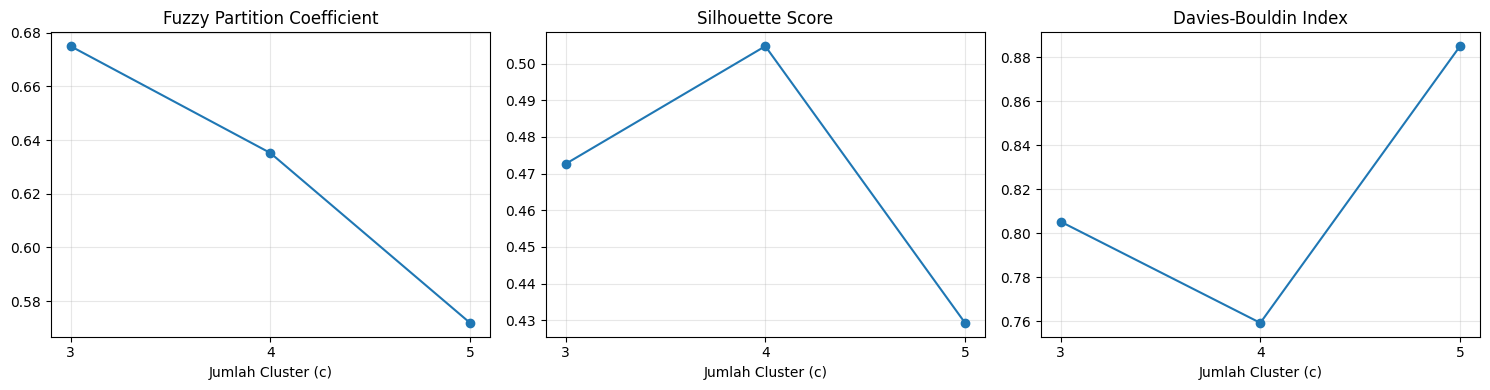

In [33]:

# Cell 28 - Visualisasi metrik evaluasi FCM

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ("FPC", "Fuzzy Partition Coefficient"),
    ("Silhouette", "Silhouette Score"),
    ("DBI", "Davies-Bouldin Index")
]

for ax, (column, title) in zip(axes, metrics):

    ax.plot(
        df_sensitivity["Jumlah_Cluster"],
        df_sensitivity[column],
        marker="o"
    )

    ax.set_title(title)
    ax.set_xlabel("Jumlah Cluster (c)")
    ax.set_xticks(cluster_values)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [34]:

# Cell 29 - Pengujian sensitivitas parameter fuzziness (m)

m_values = [1.5, 2.0, 2.5]
c = 4

fuzziness_results = []
fcm_fuzziness_models = {}

for m_test in m_values:

    cntr_test, u_test, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
        data=X_fcm,
        c=c,
        m=m_test,
        error=0.005,
        maxiter=1000,
        init=None,
        seed=42
    )

    labels = np.argmax(u_test, axis=0)

    silhouette = silhouette_score(X_scaled, labels)
    dbi = davies_bouldin_score(X_scaled, labels)

    cluster_counts = np.bincount(labels, minlength=c)

    fuzziness_results.append({
        "Fuzziness_m": m_test,
        "Iterasi": len(jm),
        "FPC": fpc,
        "Silhouette": silhouette,
        "DBI": dbi,
        "Distribusi_Cluster": cluster_counts.tolist()
    })

    fcm_fuzziness_models[m_test] = {
        "centers": cntr_test,
        "membership": u_test,
        "labels": labels,
        "objective": jm
    }

df_fuzziness = pd.DataFrame(fuzziness_results)

display(df_fuzziness.round(4))


,Fuzziness_m,Iterasi,FPC,Silhouette,DBI,Distribusi_Cluster
0,1.5,27,0.8803,0.5029,0.7757,"[198, 126, 602, 377]"
1,2.0,88,0.6352,0.5047,0.7592,"[377, 120, 608, 198]"
2,2.5,43,0.4222,0.3665,0.9927,"[417, 309, 209, 368]"


In [37]:

# Cell 30 - Fungsi rekomendasi untuk setiap konfigurasi FCM

from sklearn.neighbors import NearestNeighbors

def recommend_with_fcm_params(
    specs,
    m_value,
    n_recommendations=5
):
    # Ambil model FCM sesuai nilai fuzziness
    fcm_model = fcm_fuzziness_models[m_value]

    centers = fcm_model["centers"]
    train_membership = fcm_model["membership"]

    # Bangun representasi data latih:
    # 7 fitur asli + 4 membership FCM
    X_train_hybrid = np.hstack([
        X_scaled.values,
        train_membership.T
    ])

    # Latih KNN khusus konfigurasi m ini
    model = NearestNeighbors(
        n_neighbors=n_recommendations,
        metric="euclidean",
        algorithm="brute"
    )

    model.fit(X_train_hybrid)

    # Siapkan spesifikasi laptop target
    target = pd.DataFrame([{
        col: specs[col] for col in feature_columns
    }])

    target[log_columns] = np.log1p(target[log_columns])

    target_scaled = scaler.transform(target)

    # Prediksi membership FCM untuk laptop target
    membership, _, _, _, _, _ = fuzz.cluster.cmeans_predict(
        test_data=target_scaled.T,
        cntr_trained=centers,
        m=m_value,
        error=0.005,
        maxiter=1000,
        seed=42
    )

    # Gabungkan fitur target dan membership
    query_hybrid = np.hstack([
        target_scaled,
        membership.T
    ])

    distances, indices = model.kneighbors(query_hybrid)

    result = df_original.iloc[indices[0]].copy()
    result["Distance"] = distances[0]

    return result


In [38]:

# Cell 31 - Perbandingan rekomendasi untuk setiap nilai m

test_profiles = {
    "Profil A - Ekonomis": {
        "Price_euros": 700,
        "Ram_GB": 8,
        "Weight_kg": 1.3,
        "SSD_GB": 256,
        "HDD_GB": 0,
        "CPU_Family_Score": 3,
        "CPU_Base_GHz": 2.4
    },

    "Profil B - Produktivitas": {
        "Price_euros": 1200,
        "Ram_GB": 16,
        "Weight_kg": 1.6,
        "SSD_GB": 512,
        "HDD_GB": 0,
        "CPU_Family_Score": 7,
        "CPU_Base_GHz": 2.8
    },

    "Profil C - Performa Tinggi": {
        "Price_euros": 2000,
        "Ram_GB": 32,
        "Weight_kg": 2.2,
        "SSD_GB": 1024,
        "HDD_GB": 0,
        "CPU_Family_Score": 9,
        "CPU_Base_GHz": 3.2
    }
}

m_test_values = [1.5, 2.0, 2.5]

recommendation_results = {}

for profile_name, specs in test_profiles.items():

    recommendation_results[profile_name] = {}

    for m_value in m_test_values:

        result = recommend_with_fcm_params(
            specs=specs,
            m_value=m_value,
            n_recommendations=5
        )

        recommendation_results[profile_name][m_value] = result

        print(f"\n{profile_name} | m = {m_value}")

        display(
            result[
                ["Company", "Product", "Price_euros",
                 "Ram", "Memory", "CPU", "Weight", "Distance"]
            ]
        )



Profil A - Ekonomis | m = 1.5


KeyError: "['CPU'] not in index"